In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
data = pd.read_csv("student_success_expanded_balanced.csv")

In [46]:
data.shape

(951, 21)

In [47]:
data.head()

,StudentID,Age,Gender,Country,AttendanceRate,StudyHoursPerWeek,SleepHours,InternetSpeedMbps,DeviceType,PreviousGPA,...,CommuteMins,Tutoring,ParentalEducation,LearningStyle,ExtracurricularHours,QuizScore,AssignmentScore,MidtermScore,FinalScore,Result
0,10001,23.0,Male,India,0.924543,9.726927,6.165822,17.297479,Laptop,2.870025,...,44.624160,No,Masters,Reading,6.773810,79.483523,68.059875,61.875194,78.494855,Fail
1,10002,31.0,Male,Pakistan,0.769927,7.454582,6.804910,9.786828,Laptop,3.091862,...,54.964167,Yes,Masters,Visual,0.000000,79.738937,68.226311,72.946944,90.050467,Pass
2,10003,27.0,Male,Sri Lanka,0.995969,6.581002,9.503604,9.671157,Desktop,2.768614,...,63.023413,No,HighSchool,Kinesthetic,4.274718,80.970310,90.955478,80.861034,90.050236,Pass
3,10004,24.0,Male,India,0.875446,11.977052,5.586163,17.520781,Laptop,2.134015,...,74.240715,Yes,HighSchool,Auditory,4.794347,94.394513,77.504459,96.472820,82.489804,Pass
4,10005,23.0,Female,Sri Lanka,0.803905,0.896958,9.422168,29.734222,Mobile,2.858312,...,33.313836,No,HighSchool,Visual,5.867407,82.008211,72.318216,83.729495,66.509613,Fail


In [48]:
data.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Country,0
AttendanceRate,0
StudyHoursPerWeek,0
SleepHours,0
InternetSpeedMbps,0
DeviceType,0
PreviousGPA,0


In [49]:
data.describe()

,StudentID,Age,AttendanceRate,StudyHoursPerWeek,SleepHours,InternetSpeedMbps,PreviousGPA,PartTimeJobHours,CommuteMins,ExtracurricularHours,QuizScore,AssignmentScore,MidtermScore,FinalScore
count,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000,951.000000
mean,10499.113565,25.167057,0.813705,10.193601,6.934026,21.595353,2.579272,10.525211,37.225112,3.123882,79.764594,79.914749,78.101183,81.579863
std,289.359805,5.209007,0.132792,6.686693,1.489872,11.759289,0.722045,6.753640,26.855682,2.214149,10.925475,10.842959,11.838233,13.419240
min,10001.000000,17.000000,0.367073,0.000000,3.000000,1.000000,0.018144,0.000000,0.000000,0.000000,45.036478,45.892949,36.259906,21.620242
25%,10247.500000,21.000000,0.723323,5.575975,5.968075,13.474640,2.081957,5.523592,20.227607,1.359069,72.725960,72.435403,70.184173,72.874573
50%,10499.000000,25.000000,0.820506,9.998118,6.978852,21.305107,2.580247,10.240334,35.790549,2.972652,79.738937,79.891523,78.628185,82.257791
75%,10748.500000,30.000000,0.918636,14.102732,7.950241,29.331150,3.091818,15.080574,51.751288,4.628077,87.158411,87.212810,86.380305,92.397424
max,11000.000000,34.000000,1.000000,60.000000,11.000000,59.354922,4.000000,33.641680,240.000000,10.423774,100.000000,100.000000,100.000000,100.000000


In [50]:
data = pd.get_dummies(data, columns=['Gender', 'Country', 'DeviceType', 'Tutoring', 'ParentalEducation', 'LearningStyle'])

In [51]:
data.head()

,StudentID,Age,AttendanceRate,StudyHoursPerWeek,SleepHours,InternetSpeedMbps,PreviousGPA,PartTimeJobHours,CommuteMins,ExtracurricularHours,...,DeviceType_Tablet,Tutoring_No,Tutoring_Yes,ParentalEducation_Bachelor,ParentalEducation_HighSchool,ParentalEducation_Masters,LearningStyle_Auditory,LearningStyle_Kinesthetic,LearningStyle_Reading,LearningStyle_Visual
0,10001,23.0,0.924543,9.726927,6.165822,17.297479,2.870025,9.971490,44.624160,6.773810,...,False,True,False,False,False,True,False,False,True,False
1,10002,31.0,0.769927,7.454582,6.804910,9.786828,3.091862,9.711182,54.964167,0.000000,...,False,False,True,False,False,True,False,False,False,True
2,10003,27.0,0.995969,6.581002,9.503604,9.671157,2.768614,15.248218,63.023413,4.274718,...,False,True,False,False,True,False,False,True,False,False
3,10004,24.0,0.875446,11.977052,5.586163,17.520781,2.134015,0.000000,74.240715,4.794347,...,False,False,True,False,True,False,True,False,False,False
4,10005,23.0,0.803905,0.896958,9.422168,29.734222,2.858312,12.340289,33.313836,5.867407,...,False,True,False,False,True,False,False,False,False,True


In [52]:
data['Result'] = data['Result'].map({'Pass': 1, 'Fail': 0})

In [53]:
data['Result']

,Result
0,0
1,1
2,1
3,1
4,0
...,...
946,1
947,0
948,1
949,1


In [54]:
X = data.drop('Result', axis=1)
y = data['Result']

In [55]:
from sklearn.preprocessing import StandardScaler

In [56]:
scale = StandardScaler()
X = scale.fit_transform(X)

In [58]:
from sklearn.model_selection import train_test_split

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

In [60]:
X.shape

(951, 34)

In [61]:
X_train.shape

(760, 34)

In [62]:
X_test.shape

(191, 34)

In [63]:
from tensorflow import keras
from tensorflow.keras import layers

In [65]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

In [66]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [72]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         2,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,061 (51.02 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,708 (34.02 KB)

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=2
)

Epoch 1/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6349 - loss: 0.6244 - val_accuracy: 0.7763 - val_loss: 0.5133
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8406 - loss: 0.4616 - val_accuracy: 0.8289 - val_loss: 0.4172
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8903 - loss: 0.3548 - val_accuracy: 0.8487 - val_loss: 0.3509
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9165 - loss: 0.2805 - val_accuracy: 0.8487 - val_loss: 0.3083
Epoch 5/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9274 - loss: 0.2244 - val_accuracy: 0.8618 - val_loss: 0.2801
Epoch 6/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9352 - loss: 0.2030 - val_accuracy: 0.8684 - val_loss: 0.2525
Epoch 7/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9658 - loss: 0.1468 - val_accuracy: 0.8816 - val_loss: 0.2411
Epoch 8/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9747 - loss: 0.1201 - val_accuracy: 0.8947 - val_loss

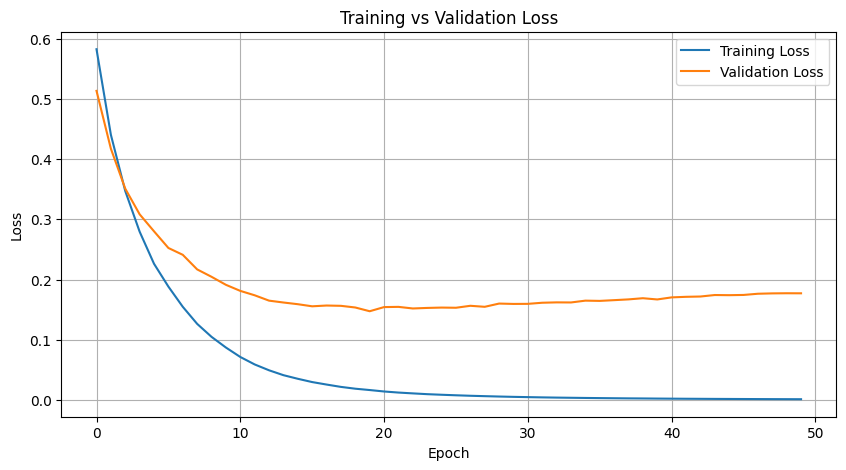

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


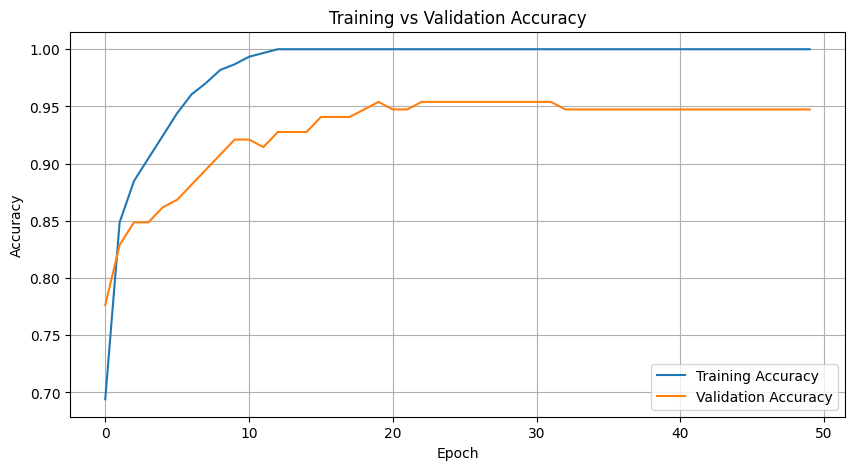

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
#The model showed clear signs of overfitting.

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc}')
print(f'Test loss: {test_loss}')


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9244 - loss: 0.2279 
Test accuracy: 0.926701545715332
Test loss: 0.21646952629089355


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


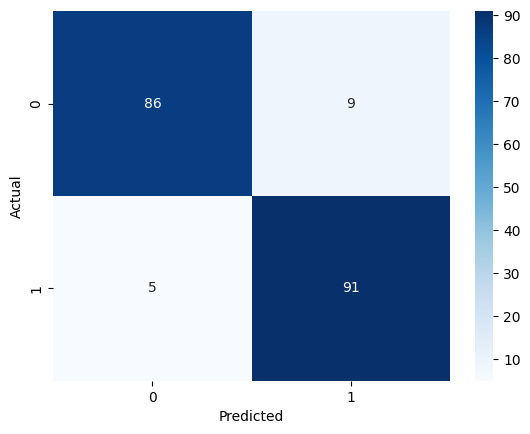

              precision    recall  f1-score   support

           0       0.95      0.91      0.92        95
           1       0.91      0.95      0.93        96

    accuracy                           0.93       191
   macro avg       0.93      0.93      0.93       191
weighted avg       0.93      0.93      0.93       191



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(X_test) > 0.5).astype("int32")

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, y_pred))


In [ ]:
#No.the model is not biased toward one class